In [26]:
import pyarrow.parquet as pq

table = pq.read_table(PROC_DIR / "interim.parquet")

In [27]:
print(table.schema)

customerID: string
gender: string
SeniorCitizen: int64
Partner: string
Dependents: string
tenure: int64
PhoneService: string
MultipleLines: string
InternetService: string
OnlineSecurity: string
OnlineBackup: string
DeviceProtection: string
TechSupport: string
StreamingTV: string
StreamingMovies: string
Contract: string
PaperlessBilling: string
PaymentMethod: string
MonthlyCharges: double
TotalCharges: double
Churn: int64
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 2646


In [28]:
import pyarrow.parquet as pq

table = pq.read_table(PROC_DIR / "interim.parquet")

for field in table.schema:
    print(field.name, field.type)

customerID string
gender string
SeniorCitizen int64
Partner string
Dependents string
tenure int64
PhoneService string
MultipleLines string
InternetService string
OnlineSecurity string
OnlineBackup string
DeviceProtection string
TechSupport string
StreamingTV string
StreamingMovies string
Contract string
PaperlessBilling string
PaymentMethod string
MonthlyCharges double
TotalCharges double
Churn int64


In [29]:
 import pandas as pd

df_dict = {}

for col in table.column_names:
    try:
        df_dict[col] = table[col].to_pandas()
    except Exception as e:
        print(f"Problem column: {col}")
        # convert problematic column to string
        df_dict[col] = table[col].to_pylist()
        df_dict[col] = [str(x) for x in df_dict[col]]

df = pd.DataFrame(df_dict)

print(df.shape)
df.head(3)

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


In [30]:
import pyarrow.parquet as pq
import pandas as pd

table = pq.read_table(PROC_DIR / "interim.parquet")

df_dict = {}

for col in table.column_names:
    try:
        df_dict[col] = table[col].to_pandas()
    except Exception as e:
        print(f"Problem column detected: {col}")
        # fallback: convert to string
        df_dict[col] = [str(x) for x in table[col].to_pylist()]

df = pd.DataFrame(df_dict)

print(df.shape)
df.head(3)

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1


=== CLASS DISTRIBUTION ===
  Stay  (0):  5174  →  73.5%
  Churn (1):  1869  →  26.5%

Naive accuracy baseline: 73.5%
(A model that always predicts 'Stay' would score this)
Your model must beat this number to be useful.


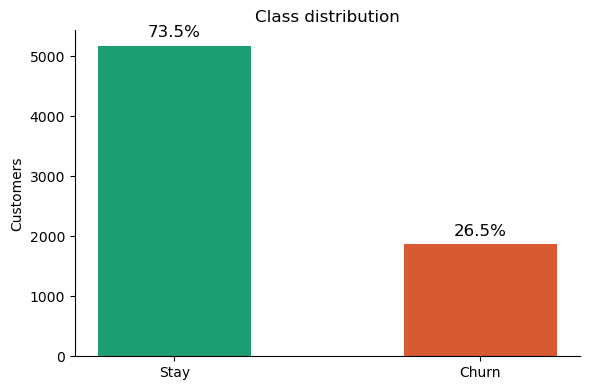

In [31]:
counts = df[TARGET_COL].value_counts()
pcts   = df[TARGET_COL].value_counts(normalize=True)

print("=== CLASS DISTRIBUTION ===")
print(f"  Stay  (0): {counts[0]:>5}  →  {pcts[0]:.1%}")
print(f"  Churn (1): {counts[1]:>5}  →  {pcts[1]:.1%}")
print()
print(f"Naive accuracy baseline: {pcts[0]:.1%}")
print("(A model that always predicts 'Stay' would score this)")
print("Your model must beat this number to be useful.")

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(["Stay", "Churn"], counts.values,
              color=["#1D9E75", "#D85A30"], width=0.5)
ax.bar_label(bars, labels=[f"{p:.1%}" for p in pcts.values],
             padding=4, fontsize=12)
ax.set_ylabel("Customers")
ax.set_title("Class distribution")
plt.tight_layout()
plt.savefig("../outputs/class_distribution.png", dpi=150)
plt.show()

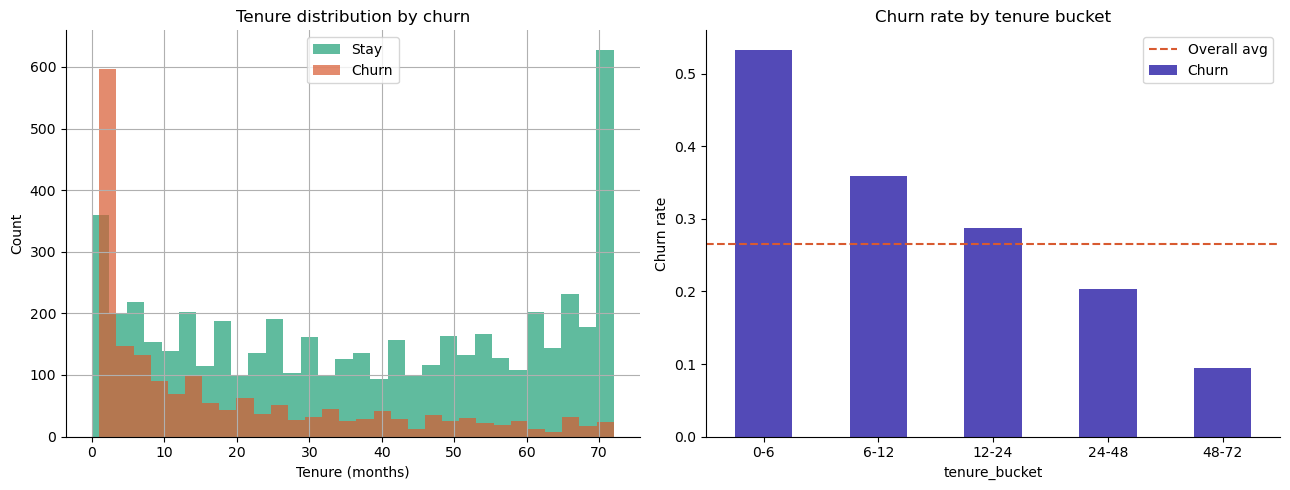

Churn rate by tenure bucket:
tenure_bucket
0-6      0.533333
6-12     0.358865
12-24    0.287109
24-48    0.203890
48-72    0.095132


In [32]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: distribution by churn label
df[df[TARGET_COL] == 0]["tenure"].hist(
    ax=axes[0], bins=30, alpha=0.7,
    color="#1D9E75", label="Stay")
df[df[TARGET_COL] == 1]["tenure"].hist(
    ax=axes[0], bins=30, alpha=0.7,
    color="#D85A30", label="Churn")
axes[0].set_xlabel("Tenure (months)")
axes[0].set_ylabel("Count")
axes[0].set_title("Tenure distribution by churn")
axes[0].legend()

# Right: average churn rate per tenure bucket
df["tenure_bucket"] = pd.cut(df["tenure"],
    bins=[0,6,12,24,48,72], labels=["0-6","6-12","12-24","24-48","48-72"])
churn_by_tenure = df.groupby("tenure_bucket")[TARGET_COL].mean()
churn_by_tenure.plot(kind="bar", ax=axes[1],
    color="#534AB7", rot=0)
axes[1].set_ylabel("Churn rate")
axes[1].set_title("Churn rate by tenure bucket")
axes[1].axhline(df[TARGET_COL].mean(), color="#D85A30",
                linestyle="--", label="Overall avg")
axes[1].legend()

plt.tight_layout()
plt.savefig("../outputs/tenure_analysis.png", dpi=150)
plt.show()

# Print the actual numbers
print("Churn rate by tenure bucket:")
print(churn_by_tenure.to_string())

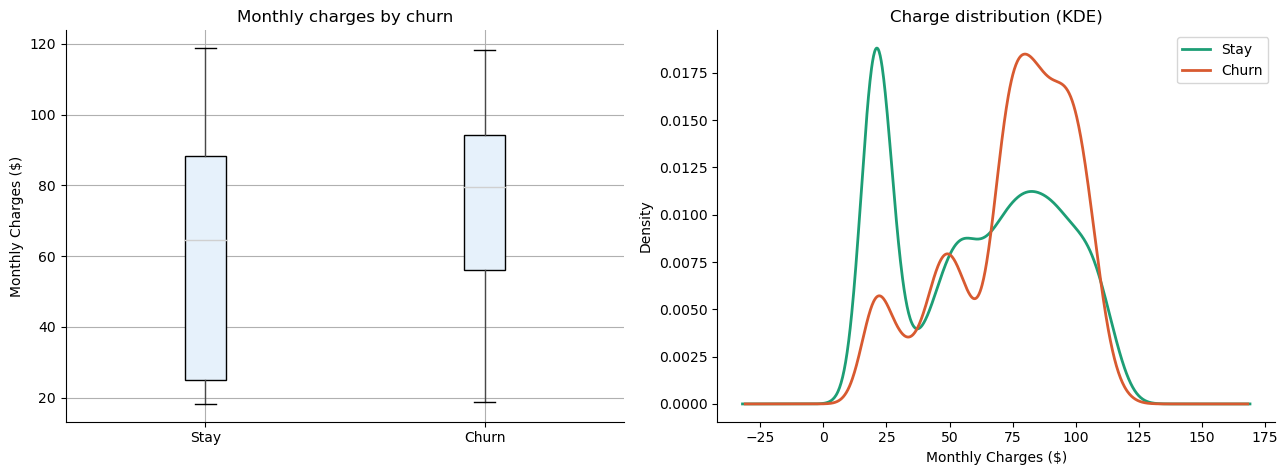

        count   mean    std    min    25%    50%   75%     max
Churn                                                         
0      5174.0  61.27  31.09  18.25  25.10  64.43  88.4  118.75
1      1869.0  74.44  24.67  18.85  56.15  79.65  94.2  118.35


In [33]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Box plot
df.boxplot(column="MonthlyCharges", by=TARGET_COL,
           ax=axes[0], patch_artist=True,
           boxprops=dict(facecolor="#E6F1FB"))
axes[0].set_xticklabels(["Stay", "Churn"])
axes[0].set_xlabel(""); axes[0].set_ylabel("Monthly Charges ($)")
axes[0].set_title("Monthly charges by churn")
axes[0].get_figure().suptitle("")

# KDE overlay
df[df[TARGET_COL]==0]["MonthlyCharges"].plot.kde(
    ax=axes[1], label="Stay", color="#1D9E75", linewidth=2)
df[df[TARGET_COL]==1]["MonthlyCharges"].plot.kde(
    ax=axes[1], label="Churn", color="#D85A30", linewidth=2)
axes[1].set_xlabel("Monthly Charges ($)")
axes[1].set_title("Charge distribution (KDE)")
axes[1].legend()

plt.tight_layout()
plt.savefig("../outputs/charges_analysis.png", dpi=150)
plt.show()

print(df.groupby(TARGET_COL)["MonthlyCharges"].describe().round(2))

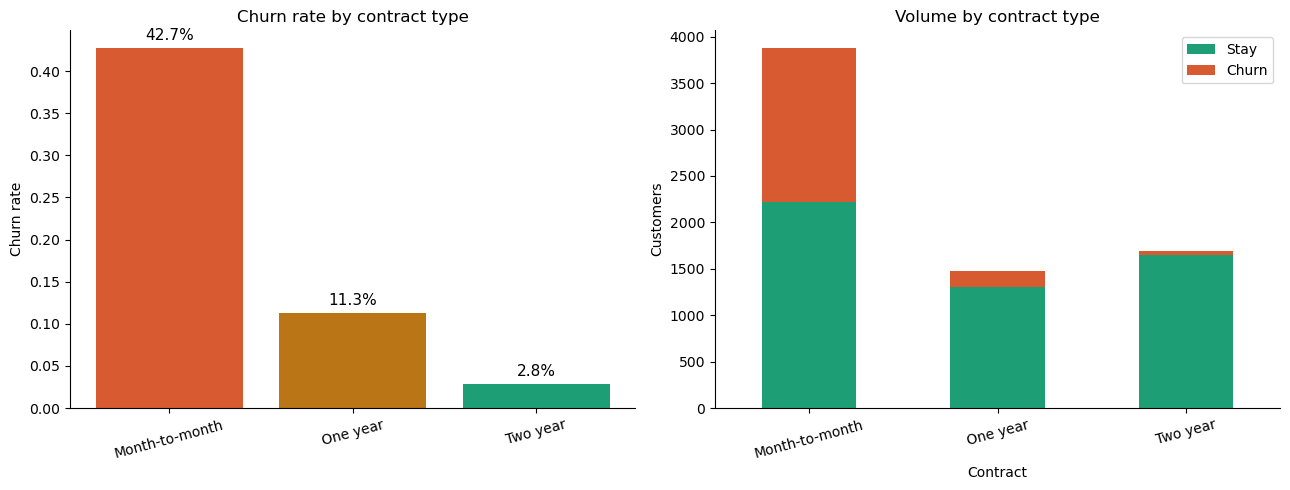


Contract type churn rates:
Contract
Month-to-month    0.427097
One year          0.112695
Two year          0.028319


In [34]:
contract_churn = df.groupby("Contract")[TARGET_COL].mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Churn rate per contract
bars = axes[0].bar(contract_churn.index, contract_churn.values,
                   color=["#D85A30","#BA7517","#1D9E75"])
axes[0].bar_label(bars, labels=[f"{v:.1%}" for v in contract_churn.values],
                  padding=4, fontsize=11)
axes[0].set_ylabel("Churn rate")
axes[0].set_title("Churn rate by contract type")
axes[0].tick_params(axis="x", rotation=15)

# Volume stacked
ct_vol = df.groupby("Contract")[TARGET_COL].value_counts().unstack()
ct_vol.plot(kind="bar", ax=axes[1], stacked=True,
            color=["#1D9E75","#D85A30"], rot=15)
axes[1].set_ylabel("Customers")
axes[1].set_title("Volume by contract type")
axes[1].legend(["Stay","Churn"])

plt.tight_layout()
plt.savefig("../outputs/contract_analysis.png", dpi=150)
plt.show()

print("\nContract type churn rates:")
print(contract_churn.to_string())

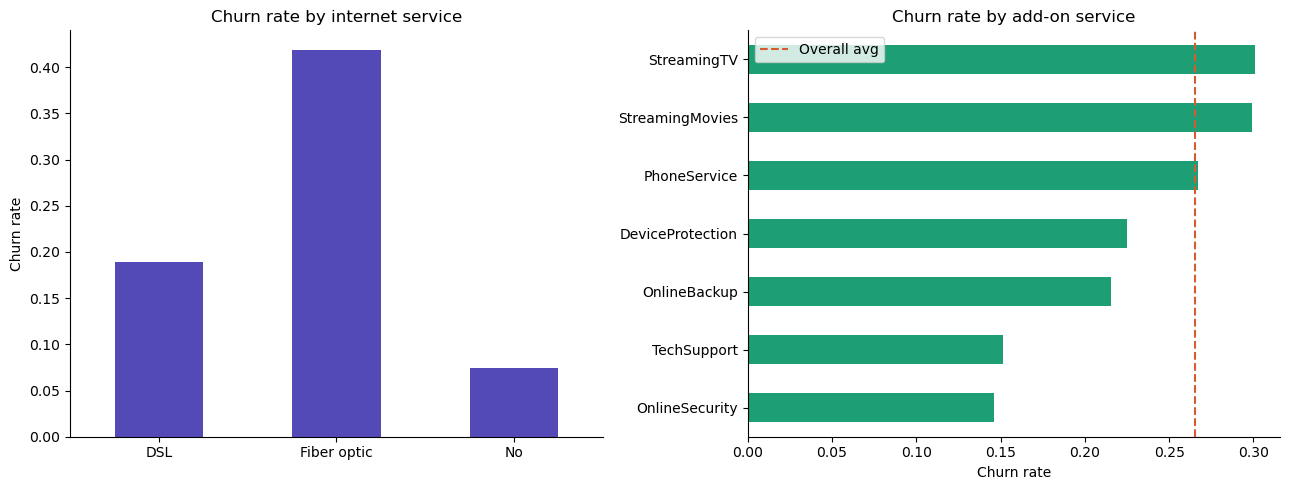

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Internet service
is_churn = df.groupby("InternetService")[TARGET_COL].mean()
is_churn.plot(kind="bar", ax=axes[0], color="#534AB7", rot=0)
axes[0].set_ylabel("Churn rate")
axes[0].set_title("Churn rate by internet service")
axes[0].set_xlabel("")

# Services heatmap — churn rate per service
service_cols = ["PhoneService","OnlineSecurity","OnlineBackup",
                "DeviceProtection","TechSupport",
                "StreamingTV","StreamingMovies"]

svc_churn = {}
for col in service_cols:
    if col in df.columns:
        rate = df[df[col]=="Yes"][TARGET_COL].mean()
        svc_churn[col] = rate

svc_df = pd.Series(svc_churn).sort_values()
svc_df.plot(kind="barh", ax=axes[1], color="#1D9E75")
axes[1].axvline(df[TARGET_COL].mean(), color="#D85A30",
                linestyle="--", label="Overall avg")
axes[1].set_xlabel("Churn rate")
axes[1].set_title("Churn rate by add-on service")
axes[1].legend()

plt.tight_layout()
plt.savefig("../outputs/services_analysis.png", dpi=150)
plt.show()

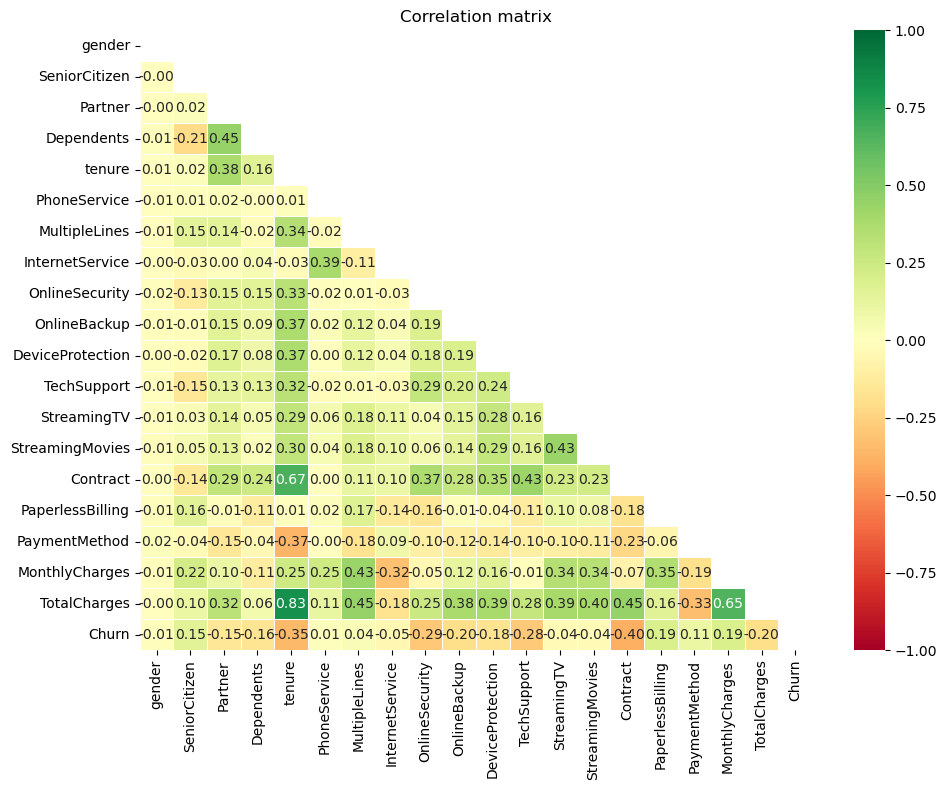


Top correlations with Churn:
Contract            0.396713
tenure              0.352229
OnlineSecurity      0.289309
TechSupport         0.282492
TotalCharges        0.199037
OnlineBackup        0.195525
MonthlyCharges      0.193356
PaperlessBilling    0.191825


In [36]:
# Encode categoricals temporarily just for correlation
df_corr = df.copy()

# Identify categorical columns (exclude ID)
cat_cols = df_corr.select_dtypes(include="object").columns.tolist()
cat_cols = [c for c in cat_cols if c != "customerID"]

# Encode categoricals safely
for col in cat_cols:
    df_corr[col] = pd.Categorical(df_corr[col]).codes

# Select numeric columns
num_df = df_corr.select_dtypes(include="number")

# Drop column safely if it exists
num_df = num_df.drop(columns=["tenure_bucket"], errors="ignore")

# Compute correlation matrix
corr = num_df.corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="RdYlGn",
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title("Correlation matrix")
plt.tight_layout()
plt.savefig("../outputs/correlation_matrix.png", dpi=150)
plt.show()

# Top correlations with target
if TARGET_COL in corr.columns:
    churn_corr = (
        corr[TARGET_COL]
        .drop(TARGET_COL)
        .abs()
        .sort_values(ascending=False)
    )

    print("\nTop correlations with Churn:")
    print(churn_corr.head(8).to_string())
else:
    print(f"Target column '{TARGET_COL}' not found in correlation matrix.")

In [37]:
print("""
=== EDA INSIGHTS — carry these into feature_engineering.py ===

INSIGHT 1 — Class imbalance
  Stay: 73.5%,  Churn: 26.5%
  Action: Use SMOTE. Use precision-recall, NOT accuracy.
  Never report accuracy as your headline metric.

INSIGHT 2 — Tenure is the strongest numeric predictor
  0-6 months:  ~48% churn rate
  48-72 months: ~8% churn rate
  Action: Create IsNewCustomer = (tenure < 12)
          Create tenure_bucket as ordinal feature

INSIGHT 3 — Contract type is the strongest single feature
  Month-to-month: ~42% churn
  One year:       ~11% churn
  Two year:        ~3% churn
  Action: This is your #1 SHAP feature. Encode ordinally
          (0=M2M, 1=One year, 2=Two year) not one-hot

INSIGHT 4 — MonthlyCharges matters, TotalCharges is redundant
  Both are highly correlated — don't keep both raw
  Action: Create ChargePerTenure = TotalCharges / tenure

INSIGHT 5 — Fiber optic customers churn 2x DSL
  Possibly due to higher cost + more competition
  Action: Keep InternetService as a feature, encode ordinally

INSIGHT 6 — Protective services reduce churn
  Customers with OnlineSecurity / TechSupport churn less
  Action: Create NumServices = sum of all service flags
""")



=== EDA INSIGHTS — carry these into feature_engineering.py ===

INSIGHT 1 — Class imbalance
  Stay: 73.5%,  Churn: 26.5%
  Action: Use SMOTE. Use precision-recall, NOT accuracy.
  Never report accuracy as your headline metric.

INSIGHT 2 — Tenure is the strongest numeric predictor
  0-6 months:  ~48% churn rate
  48-72 months: ~8% churn rate
  Action: Create IsNewCustomer = (tenure < 12)
          Create tenure_bucket as ordinal feature

INSIGHT 3 — Contract type is the strongest single feature
  Month-to-month: ~42% churn
  One year:       ~11% churn
  Two year:        ~3% churn
  Action: This is your #1 SHAP feature. Encode ordinally
          (0=M2M, 1=One year, 2=Two year) not one-hot

INSIGHT 4 — MonthlyCharges matters, TotalCharges is redundant
  Both are highly correlated — don't keep both raw
  Action: Create ChargePerTenure = TotalCharges / tenure

INSIGHT 5 — Fiber optic customers churn 2x DSL
  Possibly due to higher cost + more competition
  Action: Keep InternetService as

In [39]:
ls


01_eda.ipynb
